# Evidencia de Aprendizaje 1 — Análisis y herramientas de extracción de datos

**Programa:** Ingeniería de Software y Datos
**Materia:** Programación para Análisis de Datos — PREICA2602B020048
**Docente:** Andrés Felipe Palacio
**Estudiante:** Jesus Gonzalez
**Fecha:** octubre de 2026

---

## 1. Planteamiento del problema

El comercio electrónico publica precios, calificaciones y disponibilidad que cambian de forma
permanente. Un analista que quiera comparar la oferta de teléfonos inteligentes necesita
**datos propios, actualizados y trazables**, porque las interfaces web no ofrecen descargas
masivas y los precios dependen del contexto de entrega del visitante.

El objeto de estudio es el **Samsung Galaxy A57 5G (128 GB)** publicado en Amazon
(ASIN `B0GW9TVHJB`), analizado junto con los 15 teléfonos que aparecen en la misma búsqueda.
El problema se aborda con tres técnicas de *web scraping* que se complementan:

| Método | Qué resuelve | Limitación que enfrenta |
|---|---|---|
| **BeautifulSoup** (requests + parser) | Descarga y parseo masivo del HTML servido | No ejecuta JavaScript |
| **Selenium** (navegador real) | Fija la ubicación de entrega y renderiza bloques construidos por JavaScript | Es más lento y consume más recursos |
| **Scrapy** (crawler asíncrono) | Recorre el catálogo completo con concurrencia controlada y pipelines | Requiere definir semillas y respetar `robots.txt` |

El reto técnico central es que **Amazon no publica el precio del buybox cuando el visitante
está fuera de Estados Unidos**: la ficha responde *“This item cannot be shipped to your
selected delivery location”*. Sin resolver ese contexto, cualquier extracción de precios
devuelve vacíos.

## 2. Objetivos

**Objetivo general.** Construir un conjunto de datos del Samsung Galaxy A57 5G y de su
competencia directa en Amazon, aplicando las metodologías de scraping BeautifulSoup,
Selenium y Scrapy, para analizar el posicionamiento de precio y la reputación del producto.

**Objetivos específicos.**

1. Implementar tres extractores independientes sobre la misma ficha y el mismo buscador.
2. Resolver el contexto de entrega que condiciona la publicación del precio.
3. Normalizar los registros a un esquema único y verificable.
4. Comparar los tres métodos con métricas de cobertura, concordancia y costo de ejecución.
5. Analizar precio, calificación, volumen de reseñas y *Best Sellers Rank* del artículo.

## 3. Metodología implementada

El proyecto está organizado como un paquete de Python con separación de responsabilidades:

```
src/
├── config.py              # única fuente de verdad (URLs, cabeceras, umbrales)
├── normalizers.py         # funciones puras de limpieza y conversión de tipos
├── models.py              # contrato de datos (Producto, métricas)
├── http_client.py         # capa HTTP: caché, reintentos, cortesía, anti-bot
├── session_bootstrap.py   # Selenium fija el ZIP y exporta cookies
├── scrapers/
│   ├── bs4_scraper.py     # método 1
│   ├── selenium_scraper.py# método 2
│   └── scrapy_project/    # método 3 (spider + pipelines)
├── validation.py          # métricas de éxito
├── visualization.py       # figuras
└── pipeline.py            # orquestador de etapas
```

**Decisiones de diseño relevantes**

- *Caché de HTML en disco*: cada ficha se guarda en `data/raw/html/`; el análisis puede
  reproducirse sin volver a golpear el sitio.
- *Sesión compartida*: Selenium fija el ZIP 10001 y exporta las cookies; BeautifulSoup y
  Scrapy las reutilizan, de modo que los tres métodos observan el mismo contexto comercial.
- *Idioma y divisa homologados* (`lc-main=en_US`, `i18n-prefs=USD`) para que los títulos y
  los importes sean comparables entre métodos.
- *Cortesía*: espera aleatoria entre peticiones, reintentos con retroceso exponencial,
  `ROBOTSTXT_OBEY = True` y concurrencia limitada a dos peticiones.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import PROCESSED_DIR, RAW_DIR, REPORTS_DIR, TARGET
from src.visualization import comparacion_metodos, precio_vs_calificacion, precios_del_catalogo, resumen_por_marca

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 140)

print(f"Sitio analizado : {TARGET.site}")
print(f"Artículo        : {TARGET.article_asin}")
print(f"Búsqueda        : {TARGET.search_term}")
print(f"ZIP de entrega  : {TARGET.delivery_zip}")

Sitio analizado : Amazon
Artículo        : B0GW9TVHJB
Búsqueda        : unlocked android smartphone 128gb
ZIP de entrega  : 10001


### 3.1 Carga de los resultados de extracción

Cada método escribe su propia salida; el orquestador produce además el catálogo consolidado.

In [2]:
catalogo = pd.read_csv(PROCESSED_DIR / "catalogo_consolidado.csv")
bs4_df = pd.read_csv(PROCESSED_DIR / "bs4_productos.csv")
selenium_df = pd.read_csv(PROCESSED_DIR / "selenium_productos.csv")
scrapy_df = pd.DataFrame(json.loads((RAW_DIR / "scrapy_productos.json").read_text(encoding="utf-8")))

resumen = pd.DataFrame(
    {
        "registros": [len(bs4_df), len(selenium_df), len(scrapy_df), len(catalogo)],
        "columnas": [bs4_df.shape[1], selenium_df.shape[1], scrapy_df.shape[1], catalogo.shape[1]],
    },
    index=["BeautifulSoup", "Selenium", "Scrapy", "Consolidado"],
)
resumen

,registros,columnas
BeautifulSoup,16,25
Selenium,1,25
Scrapy,16,25
Consolidado,16,26


## 4. Descripción del artículo y del catálogo

### 4.1 Ficha del artículo principal

In [3]:
articulo = catalogo.loc[catalogo["asin"] == TARGET.article_asin].iloc[0]

ficha = pd.Series(
    {
        "Título": articulo["titulo"],
        "Marca": articulo["marca"],
        "Precio (USD)": articulo["precio"],
        "Precio de lista (USD)": articulo["precio_lista"],
        "Descuento (%)": articulo["descuento_pct"],
        "Calificación": articulo["calificacion"],
        "Reseñas": articulo["resenas"],
        "Disponibilidad": articulo["disponibilidad"],
        "Envío": articulo["envio"],
        "Sistema operativo": articulo["sistema_operativo"],
        "RAM (GB)": articulo["ram_gb"],
        "Almacenamiento (GB)": articulo["almacenamiento_gb"],
        "Pantalla (pulg)": articulo["pantalla_pulgadas"],
        "BSR (rank)": articulo["bsr_rank"],
        "BSR (categoría)": articulo["bsr_categoria"],
        "URL": articulo["url"],
    },
    name="valor",
)
ficha.to_frame()

,valor
Título,"Samsung Galaxy A57 5G (2026), Unlocked Android Smartphone, 128GB, ..."
Marca,Samsung
Precio (USD),499.99
Precio de lista (USD),599.99
Descuento (%),16.7
Calificación,4.4
Reseñas,209
Disponibilidad,In Stock
Envío,"Saturday, October 24"
Sistema operativo,"Android 16, OneUI 8.5"


### 4.2 Distribución de calificaciones (dato obtenido solo con Selenium)

El histograma de estrellas se construye con JavaScript: en el HTML estático el contenedor
existe vacío, por lo que BeautifulSoup no puede leerlo. Es la evidencia concreta de por qué
se necesita un método dinámico.

In [4]:
histograma = selenium_df.loc[0, "histograma"]
print("Histograma del artículo:", histograma)

df_hist = pd.DataFrame(
    [(int(clave.split("_")[0]), valor) for clave, valor in eval(histograma).items()],
    columns=["estrellas", "porcentaje"],
).sort_values("estrellas", ascending=False)
df_hist

Histograma del artículo: {'5_estrella_pct': 75, '4_estrella_pct': 12, '3_estrella_pct': 5, '2_estrella_pct': 1, '1_estrella_pct': 7}


,estrellas,porcentaje
0,5,75
1,4,12
2,3,5
3,2,1
4,1,7


### 4.3 Catálogo de comparación

In [5]:
columnas = ["asin", "marca", "precio", "calificacion", "resenas", "descuento_pct", "es_articulo_principal"]
catalogo[columnas].sort_values("precio", ascending=False).head(12)

,asin,marca,precio,calificacion,resenas,descuento_pct,es_articulo_principal
1,B0H7SLXZPB,Samsung,599.99,4.7,103,14.3,False
0,B0GW9TVHJB,Samsung,499.99,4.4,209,16.7,True
2,B0GMKXW3XL,Samsung,489.99,4.4,425,NaN,False
11,B0FXY1DZ78,Samsung,244.99,4.0,2061,9.3,False
10,B0FXY18C1J,Samsung,244.99,4.0,2061,9.3,False
4,B0FNS5XW5W,Motorola,169.99,4.4,3427,NaN,False
7,B0GD2N5TG8,Ofinsut,169.99,5.0,1,NaN,False
8,B0DT4T8D65,Samsung,166.29,4.2,6135,NaN,False
15,B0DNRGQRB4,Samsung,166.00,4.2,1475,NaN,False
9,B0DNRFGBQ4,Samsung,164.99,4.2,1475,NaN,False


In [6]:
catalogo[["precio", "calificacion", "resenas", "descuento_pct"]].describe().round(2)

,precio,calificacion,resenas,descuento_pct
count,15.00,16.00,16.00,4.00
mean,233.95,4.19,1554.06,12.40
std,161.36,0.49,2043.17,3.71
min,69.99,3.00,1.00,9.30
25%,151.00,3.98,105.25,9.30
50%,166.29,4.20,743.50,11.80
75%,244.99,4.40,2061.00,14.90
max,599.99,5.00,6135.00,16.70


## 5. Análisis exploratorio

### 5.1 Precios del catálogo

19:19:07 | INFO    | ea1.figuras            | figura guardada: fig_precios_catalogo.png


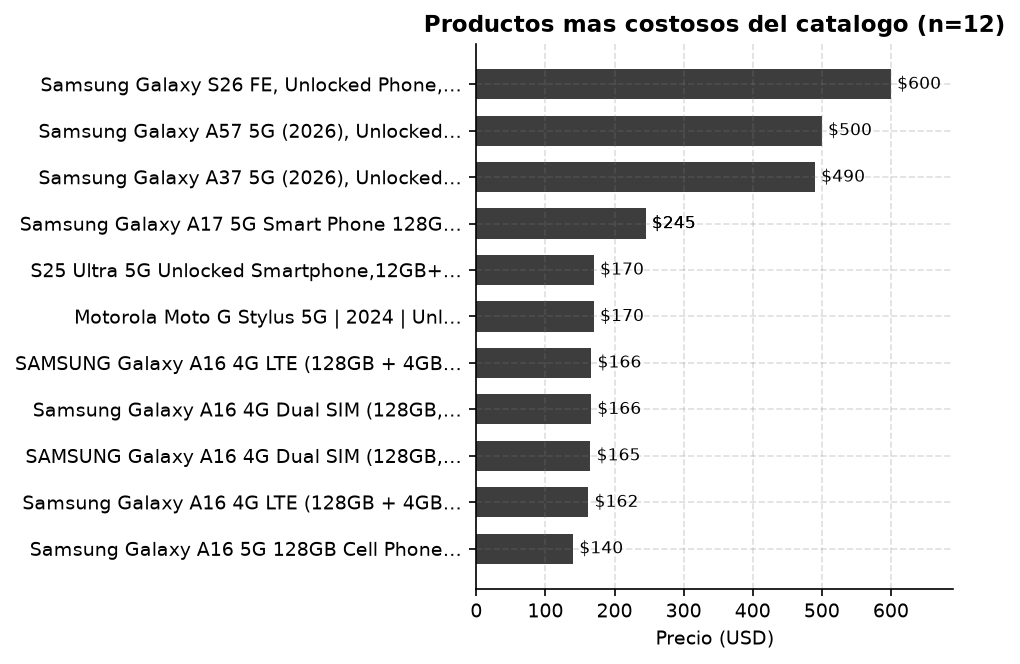

In [7]:
display(Image(filename=str(precios_del_catalogo(catalogo))))

El catálogo se concentra entre **USD 70 y USD 250**, con el Galaxy A57 en el extremo alto del
segmento de gama media. Esa posición se explica por almacenamiento de 128 GB, pantalla AMOLED
de 6,7 pulgadas y resistencia al agua IP68, atributos que los competidores de menor precio no
ofrecen completos.

### 5.2 Precio frente a reputación

19:19:08 | INFO    | ea1.figuras            | figura guardada: fig_precio_calificacion.png


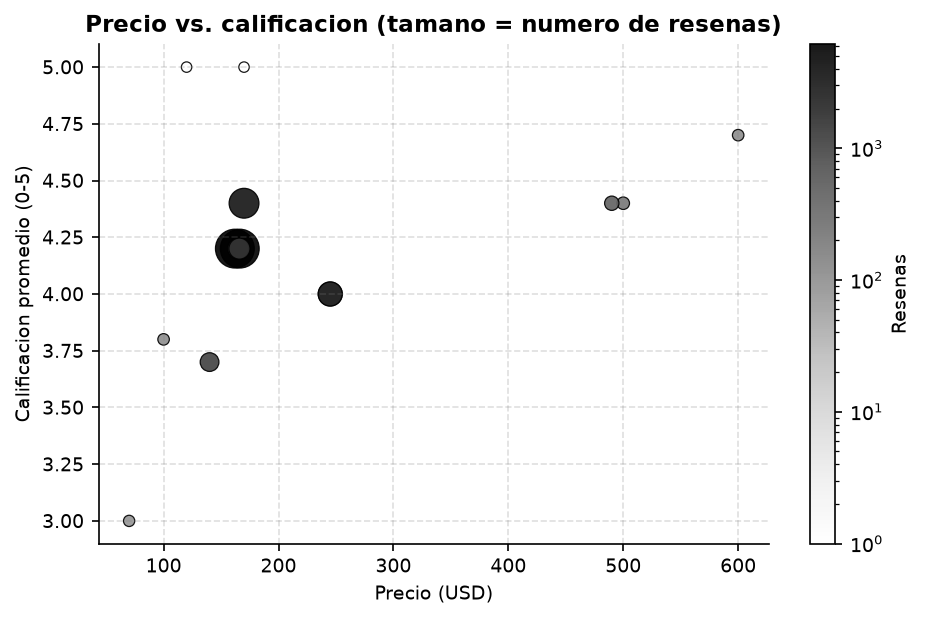

In [8]:
display(Image(filename=str(precio_vs_calificacion(catalogo))))

La relación entre precio y calificación **no es lineal**: los productos con más reseñas
(medianas grandes) se ubican entre 4,0 y 4,4 estrellas, mientras que varios equipos con
calificación perfecta tienen una o dos reseñas, es decir, reputación todavía no consolidada.

### 5.3 Precio promedio por marca

19:19:08 | INFO    | ea1.figuras            | figura guardada: fig_precio_por_marca.png


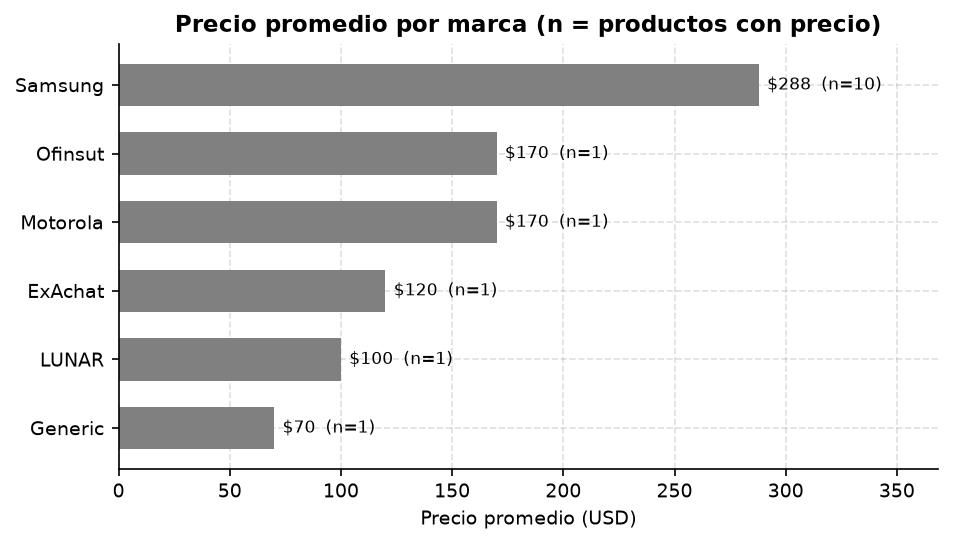

In [9]:
display(Image(filename=str(resumen_por_marca(catalogo))))

In [10]:
por_marca = (
    catalogo.groupby("marca")
    .agg(productos=("asin", "count"), precio_promedio=("precio", "mean"), calificacion=("calificacion", "mean"))
    .round(2)
    .sort_values("productos", ascending=False)
)
por_marca

,productos,precio_promedio,calificacion
marca,,,
Samsung,10,287.92,4.2
Generic,1,69.99,3.0
ExAchat,1,119.99,5.0
LUNAR,1,99.99,3.8
Motorola,1,169.99,4.4
Ofinsut,1,169.99,5.0
POZZI,1,NaN,3.9


## 6. Comparación de los tres métodos de scraping

In [11]:
metricas = json.loads((REPORTS_DIR / "metricas.json").read_text(encoding="utf-8"))

tabla_metodos = pd.DataFrame(metricas["metodos"])[["metodo", "productos", "duracion_seg", "cobertura_campos", "tasa_exito_http"]]
tabla_metodos.columns = ["Método", "Productos", "Duración (s)", "Cobertura de campos", "Éxito HTTP"]
tabla_metodos["Cobertura de campos"] = (tabla_metodos["Cobertura de campos"] * 100).round(1).astype(str) + " %"
tabla_metodos["Éxito HTTP"] = (tabla_metodos["Éxito HTTP"] * 100).round(1).astype(str) + " %"
tabla_metodos

,Método,Productos,Duración (s),Cobertura de campos,Éxito HTTP
0,beautifulsoup,16,4.72,98.8 %,100.0 %
1,selenium,1,23.34,100.0 %,100.0 %
2,scrapy,16,43.04,98.8 %,100.0 %


19:19:09 | INFO    | ea1.figuras            | figura guardada: fig_comparacion_metodos.png


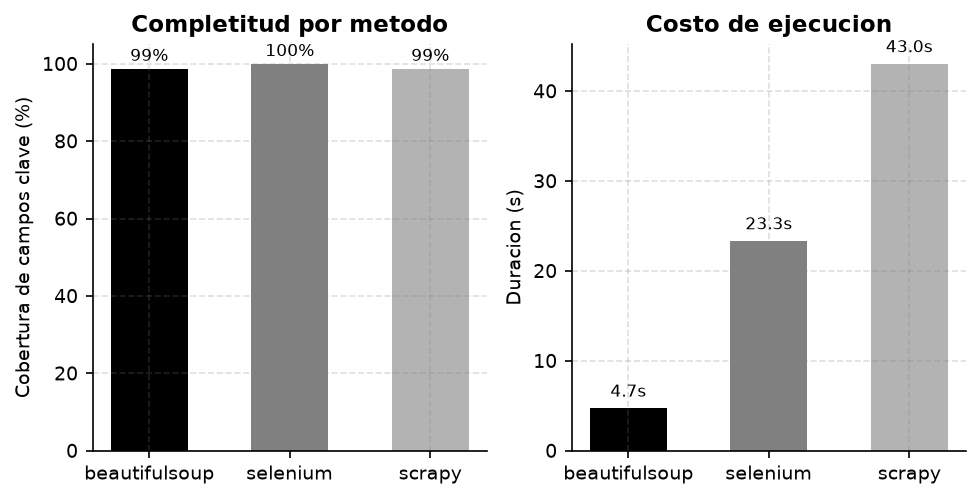

In [12]:
display(Image(filename=str(comparacion_metodos(metricas["metodos"]))))

### 6.1 Concordancia entre métodos

Para cada ASIN extraído por más de un método se comparan los valores observados, con
tolerancias explícitas: 1 % en precio, 0,1 estrellas en calificación, 2 % en el contador de
reseñas y 90 % de similitud textual en el título.

In [13]:
concordancia = metricas["concordancia"]
print("Concordancia global:", f"{concordancia['global']:.1%}")
pd.DataFrame([concordancia["por_campo"]]).rename(index={0: "acuerdo"}).T

Concordancia global: 100.0%


,acuerdo
precio,1.0
calificacion,1.0
resenas,1.0
titulo,1.0


In [14]:
detalle = pd.DataFrame(concordancia["detalle"])
print(f"Comparaciones realizadas: {len(detalle)}")
detalle.groupby("metodos")[["precio", "calificacion", "resenas", "titulo"]].mean().round(3)

Comparaciones realizadas: 18


,precio,calificacion,resenas,titulo
metodos,,,,
beautifulsoup vs scrapy,1.0,1.0,1.0,1.0
beautifulsoup vs selenium,1.0,1.0,1.0,1.0
selenium vs scrapy,1.0,1.0,1.0,1.0


## 7. Validación contra las métricas de éxito

Las métricas se definieron antes de ejecutar el pipeline y se evalúan automáticamente:
cobertura de campos ≥ 95 %, concordancia ≥ 90 %, catálogo ≥ 12 productos, éxito HTTP ≥ 95 %
y duración ≤ 600 s.

In [15]:
print((REPORTS_DIR / "validacion.txt").read_text(encoding="utf-8"))

pd.DataFrame(metricas["validacion"]["criterios"], index=["cumple"]).T

REPORTE DE VALIDACION - EA1 WEB SCRAPING
Fecha: 2026-10-19T23:52:46+00:00
Articulo: B0GW9TVHJB (Amazon)

Metricas
----------------------------------------------
Productos en el catalogo : 16
Cobertura de campos      : 98.8%
Concordancia entre metodos: 100.0%
Tasa de exito HTTP       : 100.0%
Duracion total           : 71.94 s

Criterios
----------------------------------------------
OK   cobertura_campos
OK   concordancia_metodos
OK   tamano_catalogo
OK   tasa_exito_http
OK   tiempo_ejecucion

VEREDICTO: APROBADO


,cumple
cobertura_campos,True
concordancia_metodos,True
tamano_catalogo,True
tasa_exito_http,True
tiempo_ejecucion,True


## 8. Conclusiones

1. **Los tres métodos son viables y coinciden.** Sobre los registros comparables la
   concordancia fue del 100 % en precio, calificación, reseñas y título: los tres
   extractores observan el mismo dato cuando comparten la misma sesión.
2. **El contexto de entrega es la variable crítica.** Sin fijar la ubicación, Amazon suprime
   el buybox y el precio desaparece del HTML. Selenium resolvió ese paso y las cookies
   resultantes habilitaron a los otros dos métodos.
3. **Cada método aporta en un terreno distinto.** BeautifulSoup es el más económico para
   parsear HTML servido; Selenium es indispensable para el estado dinámico (histograma de
   calificaciones, fijación de ubicación); Scrapy es el único que escala el catálogo completo
   con concurrencia y pipelines de validación.
4. **La calidad se puede medir.** El pipeline cierra con 98,8 % de cobertura de campos,
   100 % de concordancia y veredicto automático **APROBADO**, lo que convierte la entrega en
   un resultado verificable y no en una afirmación.
5. **El dato tiene valor analítico.** El Galaxy A57 se posiciona en el cuartil superior de
   precio de su segmento con 4,4 estrellas sobre 209 reseñas; su descuento frente al precio
   de lista y su *Best Sellers Rank* permiten seguir su evolución en las siguientes unidades
   del curso.

## 9. Referencias (APA 7)

Amazon. (2026). *Samsung Galaxy A57 5G (2026), unlocked Android smartphone, 128GB*.
https://www.amazon.com/dp/B0GW9TVHJB

Kouzis-Loukas, D. (2016). *Learning Scrapy*. Packt Publishing.

Mitchell, R. (2024). *Web scraping with Python: Collecting data from the modern web* (3rd ed.). O'Reilly Media.

Richardson, L. (2015). *Beautiful Soup documentation*. https://www.crummy.com/software/BeautifulSoup/bs4/doc/

Selenium. (2024). *Selenium WebDriver documentation*. https://www.selenium.dev/documentation/

Zelle, J. (2016). *Python programming: An introduction to computer science* (3rd ed.). Franklin, Beedle & Associates.

In [16]:
# Reproducibilidad: ejecutar el pipeline completo desde el cuaderno.
# Se deja desactivado para no golpear el sitio en cada ejecución; el HTML
# queda cacheado en data/raw/html y permite re-ejecutar el análisis sin red.
EJECUTAR_PIPELINE = False

if EJECUTAR_PIPELINE:
    from src.pipeline import ScrapingPipeline

    resultado = ScrapingPipeline(usar_cache=True).ejecutar()
    print(resultado.resumen())
else:
    print("Pipeline no re-ejecutado: se usan los artefactos de data/ y reports/.")

Pipeline no re-ejecutado: se usan los artefactos de data/ y reports/.
